In [1]:
%matplotlib widget
import matplotlib
import matplotlib.pyplot as plt


In [2]:
import pyvista as pv
import gstools as gs
import numpy as np
from astropy.io import fits

C:\Users\javas\anaconda3\envs\gstools_viz\Lib\site-packages\hankel\hankel.py:12: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.0)
  from scipy.integrate import quad


In [3]:
import numpy as np
import scipy
import gstools as gs
import pyvista as pv

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("GSTools:", gs.__version__)
print("PyVista:", pv.__version__)

NumPy: 2.3.0
SciPy: 1.14.1
GSTools: 1.7.0
PyVista: 0.49.1


In [4]:
pv.set_jupyter_backend("trame")
#pv.set_jupyter_backend("client")

In [5]:
N = 64
dim, spacing = (N, N, N), (1,1,1)
grid = pv.ImageData(dimensions=dim, spacing=spacing)
x = y = z = range(N)

In [6]:
field_synth = 'velocity'
model_gs    = 'stable'
alpha       = 1.5
len_scale   = [16, 16, 16]
angles      = [0, 0, 0]
seed        = 19880127
#seed       = 20170519

In [7]:
model = gs.Stable(
    dim=3,
#    var=var,
    len_scale=len_scale,
    angles=angles,
    alpha=1.5,
#    nugget=0.0,
)

In [8]:
srf = gs.SRF(
    model,
    seed=seed,
#    mode_no=3000,
)

In [9]:
field = srf.mesh

In [10]:
srf.mesh(grid, points='points', name='random-field')

array([-1.27964498, -1.36116575, -1.54150483, ...,  2.75267366,
        2.98343092,  2.83145594], shape=(262144,))

In [11]:
#grid.contour(isosurfaces=6).plot(smooth_shading=True, use_transparency=True, opacity=0.5, cmap='coolwarm')

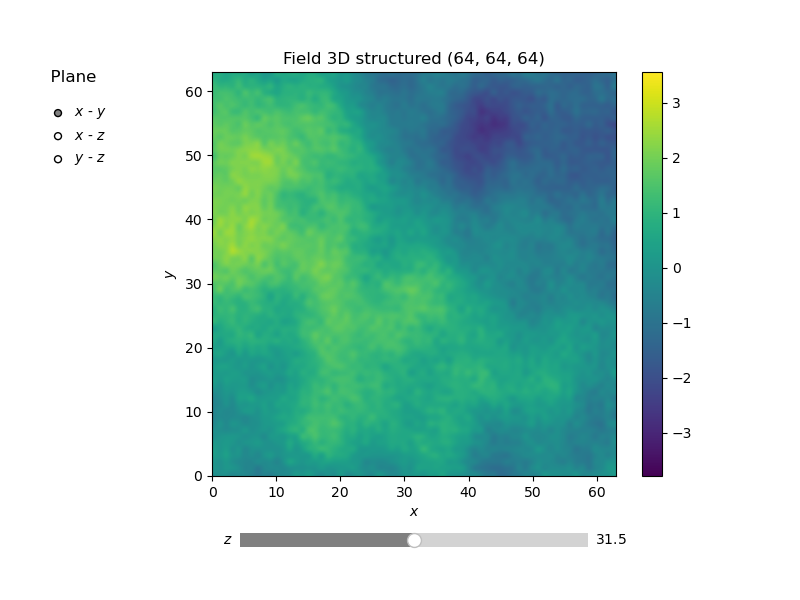

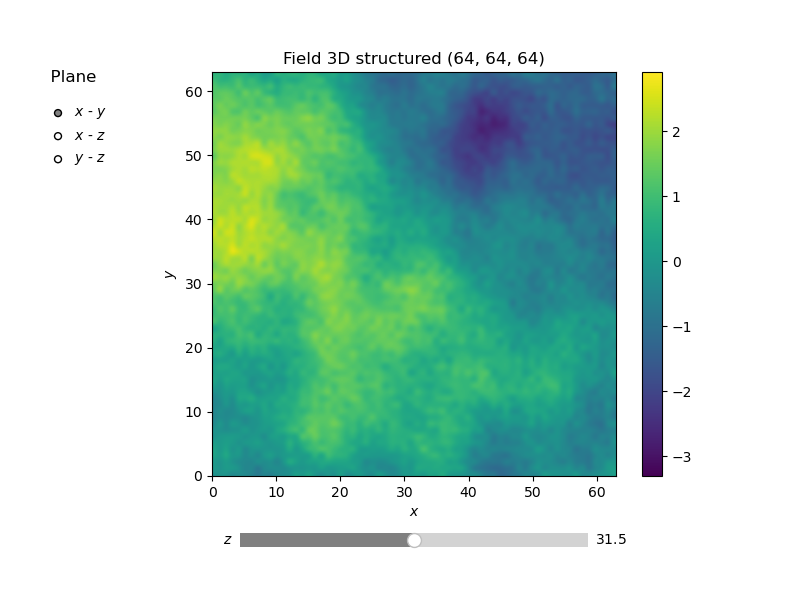

In [22]:
field = srf.structured([x, y, z])
ax = srf.plot()
#ax.images[0].set_cmap("rainbow")
ax.images[0].set_clim(vmin=-3.3, vmax=2.91)
ax.figure.canvas.draw_idle()

In [13]:
print(type(srf.field))

<class 'numpy.ndarray'>


In [14]:
print(srf.field.shape)

(64, 64, 64)


In [15]:
#field_3d = np.asarray(grid.point_data['random-field']).reshape(dim, order='F')
field_3d = srf.field.copy()

In [16]:
print(type(field_3d))
print(field_3d.shape)
print(field_3d.min())
print(field_3d.max())
print(field_3d.mean())
print(field_3d.std())

<class 'numpy.ndarray'>
(64, 64, 64)
-3.7811458675868295
3.55999993644798
0.14423516172025808
1.004965791972497


In [17]:
header = fits.Header()

header["MODEL"] = model_gs
header["SEED"]  = seed
header["M3D"]   = alpha

header["LSCALE_X"] = len_scale[0]
header["LSCALE_Y"] = len_scale[1]
header["LSCALE_Z"] = len_scale[2]

header["ANGLE_X"] = angles[0]
header["ANGLE_Y"] = angles[1]
header["ANGLE_Z"] = angles[2]

header["DX"] = spacing[0]
header["DY"] = spacing[1]
header["DZ"] = spacing[2]


In [18]:
#name = model_gs + "_3d_" + field_synth 
name = "test_field"
print(name)

test_field


In [19]:
# Change from (X, Y, Z) to (Z, Y, X)
#field_export = field_3d.transpose(2, 1, 0)

In [20]:
fits.writeto(
    name + ".fits",
    field_3d.astype("float64"),
    #field_export.astype(np.float64),
    header=header,
    overwrite=True,
)

In [21]:
xxx

NameError: name 'xxx' is not defined

In [ ]:
with fits.open(name + ".fits") as hdul:
    field_fits = hdul[0].data.copy()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# If FITS was exported after transpose(2, 1, 0),
# return to GSTools (x, y, z) ordering
field_xyz = field_fits.transpose(2, 1, 0)

# Check dimensions
assert field_xyz.shape == srf.field.shape

# Store FITS field without additional processing
srf.post_field(
    field_xyz,
    name="fits_field",
    process=False,
    save=True,
)

# Plot using GSTools
ax = srf.plot(field="fits_field")

ax.images[0].set_clim(vmin=-3.3, vmax=2.91)
ax.figure.canvas.draw_idle()

In [ ]:
np.testing.assert_array_equal(
    field_3d,
    field_xyz,
)

print("FITS export verified!")

In [ ]:
from astropy.io import fits
import numpy as np

original = np.asarray(srf.field)
#field_fits = fits.getdata("test_field.fits")
field_fits = field_xyz

print("Original shape:", original.shape)
print("FITS shape:", field_fits.shape)

print(
    "Same values:",
    np.allclose(original, field_fits)
)

print(
    "Maximum difference:",
    np.max(np.abs(original - field_fits))
)